# Podstawy AI – Logika rozmyta: decyzje i sterownik

Plan:
1. Wybór uczelni – czy operator „i” zmienia decyzję?
2. Sterownik pralki – od dwóch reguł do pełnego sterownika
3. Podsumowanie

**Jak pracujemy:**
- **TODO** w kodzie – tu piszesz kod lub zmieniasz liczby.
- **Testy** – komórka, którą uruchamiasz bez zmian. Wypisze `OK` albo `BŁĄD` z przypadkiem, który nie działa.
- **Pytanie** – odpowiadasz 2–3 zdaniami w komórce „Twoja odpowiedź”.

Kto zrobił wybór uczelni na poprzednich zajęciach, zaczyna od razu od części 2.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from functools import reduce

# ---- Gotowe funkcje z poprzednich zajęć ---------------------------------
def gamma(x, a, b):
    return np.clip((np.asarray(x, float) - a) / (b - a), 0, 1)

def L(x, a, b):
    return np.clip((b - np.asarray(x, float)) / (b - a), 0, 1)

def t(x, a, b, c):
    x = np.asarray(x, float)
    return np.clip(np.minimum((x - a) / (b - a), (c - x) / (c - b)), 0, 1)

def T_min(a, b):     return np.minimum(a, b)
def T_iloczyn(a, b): return np.asarray(a, float) * b
def T_luk(a, b):     return np.maximum(0, np.asarray(a, float) + b - 1)
def S_max(a, b):     return np.maximum(a, b)


def sprawdz(nazwa, f, przypadki):
    """Testuje funkcję f: przypadki = lista (argumenty, oczekiwany_wynik)."""
    bledy = 0
    for args, oczekiwane in przypadki:
        try:
            wynik = f(*args)
            ok = wynik is not None and np.allclose(np.asarray(wynik, float), oczekiwane, atol=1e-6, equal_nan=True)
        except Exception as e:
            wynik, ok = f"BŁĄD: {e}", False
        if not ok:
            bledy += 1
            arg = ", ".join(str(np.round(a, 3).tolist()) if isinstance(a, np.ndarray) else str(a) for a in args)
            print(f"BŁĄD  {nazwa}({arg}) = {wynik}, oczekiwano {oczekiwane}")
    print(f"OK    {nazwa}" if bledy == 0 else f"      {nazwa}: {bledy} błędnych przypadków")

---
## Część 1. Wybór uczelni – czy operator „i” zmienia decyzję?

Kandydat dostał się na 4 wydziały. Chce, żeby wydział był **wysoko w rankingu I blisko domu I miał dobrą wymianę I dawał dobre szanse na pracę**.

Dane są liczbami, a kryteria są rozmyte. Najpierw zamieniamy liczby na stopnie spełnienia kryteriów, a potem łączymy cztery kryteria operatorem „i” (t-normą).

### 1.1 Od danych do stopni

In [ ]:
wydzialy = {
    #          miejsce w rankingu, odległość [km], uczelnie partnerskie, zatrudnienie [%]
    "w1": (19, 72, 20, 78),
    "w2": (4,  92, 35, 92),
    "w3": (35, 10, 12, 70),
    "w4": (12, 50,  7, 85),
}

def kryteria(ranking, odleglosc, wymiana, praca):
    return [
        L(ranking, 5, 40),        # 'wysoko w rankingu'
        L(odleglosc, 20, 150),    # 'blisko domu'
        gamma(wymiana, 5, 30),    # 'dobra wymiana'
        gamma(praca, 60, 90),     # 'dobre szanse na pracę'
    ]

def tabela_stopni(kryteria):
    stopnie = {w: kryteria(*d) for w, d in wydzialy.items()}
    print("      ranking  blisko  wymiana  praca")
    for w, s in stopnie.items():
        print(w, "  ", "   ".join(f"{float(x):5.2f}" for x in s))
    return stopnie

stopnie = tabela_stopni(kryteria)

      ranking  blisko  wymiana  praca
w1     0.60    0.60    0.60    0.60
w2     1.00    0.45    1.00    1.00
w3     0.14    1.00    0.28    0.33
w4     0.80    0.77    0.08    0.83


### 1.2 Cztery sposoby rozumienia „i”

`reduce(T, [k1, k2, k3, k4])` liczy „k1 i k2 i k3 i k4” wybraną t-normą. Dla porównania dodajemy średnią, która **nie** jest t-normą.

In [ ]:
OPERATORY = {
    "minimum":            lambda s: float(reduce(T_min, s)),
    "iloczyn":            lambda s: float(reduce(T_iloczyn, s)),
    "Łukasiewicz":        lambda s: float(reduce(T_luk, s)),
    "średnia (to NIE i)": lambda s: float(np.mean(s)),
}

def ranking(stopnie):
    print(f"{'operator':<20}" + "".join(f"{w:>7}" for w in wydzialy) + "   kolejność")
    for nazwa, op in OPERATORY.items():
        oceny = {w: op(s) for w, s in stopnie.items()}
        kolejnosc = " > ".join(sorted(oceny, key=oceny.get, reverse=True))
        print(f"{nazwa:<20}" + "".join(f"{o:7.2f}" for o in oceny.values()) + "   " + kolejnosc)

ranking(stopnie)

operator                 w1     w2     w3     w4   kolejność
minimum                0.60   0.45   0.14   0.08   w1 > w2 > w3 > w4
iloczyn                0.13   0.45   0.01   0.04   w2 > w1 > w4 > w3
Łukasiewicz            0.00   0.45   0.00   0.00   w2 > w1 > w3 > w4
średnia (to NIE i)     0.60   0.86   0.44   0.62   w2 > w4 > w1 > w3


**Pytanie 1a.** Który wydział wygrywa przy minimum, a który przy iloczynie? Spójrz na tabelę stopni i wyjaśnij, **dlaczego** zwycięzca się zmienia.

**Pytanie 1b.** Średnia stawia w4 na drugim miejscu, choć wymiana ma tam stopień 0,08. Dlaczego średnia to nie jest „i”? Kiedy mimo to byłaby rozsądnym wyborem?


*Twoja odpowiedź:*

**Pytanie 1a:**
Przy minimum wygrywa w1, a przy iloczynie wygrywa w2. Zmiana wynika z charakterystyki operatorów, minimum bierze pod uwage najgorszą ocene z wszystkich, a w iloczynie brane są wszystkie wartości, 3 perfekcyjne wartości są zaniżane przez 4 wartość która w porównaniu z nimi jest słaba.

**Pytanie 1b:**
i" rozpatruje, czy wszystko jest dobre. Wynik nie może być lepszy niż najgorsze kryterium danego wydziału. W przypadku średniej to nie zachodzi, bo brana jest zwykła średnia.

Średnia byłaby rozsądnym wyborem w przypadku, gdy wierzymy, że za jedne słabe kryterium, inne może zrekompensować nam ten ranking.

### 1.3 Ty jesteś kandydatem

Kryteria w `kryteria()` wpisał ktoś inny. Teraz zdefiniuj je po swojemu.

1. Dla kandydata, dla którego odległość jest **bardzo** ważna, „blisko domu” znaczy co innego. Zmień to kryterium na `L(odleglosc, 10, 50)` i uruchom komórkę.
2. Potem zmień **jedno dowolne** kryterium tak, jak sam je rozumiesz.

In [ ]:
def moje_kryteria(ranking, odleglosc, wymiana, praca):
    return [
        L(ranking, 5, 40),
        L(odleglosc, 10, 50),    # TODO: zmień na L(odleglosc, 10, 50)
        gamma(wymiana, 5, 30),
        gamma(praca, 60, 90),
    ]

moje_stopnie = tabela_stopni(moje_kryteria)
print()
ranking(moje_stopnie)

      ranking  blisko  wymiana  praca
w1     0.60    0.00    0.60    0.60
w2     1.00    0.00    1.00    1.00
w3     0.14    1.00    0.28    0.33
w4     0.80    0.00    0.08    0.83

operator                 w1     w2     w3     w4   kolejność
minimum                0.00   0.00   0.14   0.00   w3 > w1 > w2 > w4
iloczyn                0.00   0.00   0.01   0.00   w3 > w1 > w2 > w4
Łukasiewicz            0.00   0.00   0.00   0.00   w1 > w2 > w3 > w4
średnia (to NIE i)     0.45   0.75   0.44   0.43   w2 > w1 > w3 > w4


**Pytanie 1c.** Kto wygrywa po zmianie „blisko domu” na `L(odleglosc, 10, 50)`? Co bardziej zmienia decyzję: wybór operatora czy definicja kryterium?

**Pytanie 1d.** Który operator najlepiej oddaje to, jak **Ty** wybierałbyś uczelnię? Uzasadnij.

*Twoja odpowiedź:*

**Pytanie 1c.** Wygrywa wydział w3, gdyż po zmniejszeniu kryterium "blisko domu" jako jedyny ma wartość równą 1. Definicja kryterium jest ważniejsza niż wybór operatora, bo źle zdefiniowane kryterium może zaburzyć wyniki niezależnie od wyboru operatora.

**Pytanie 1d.**
Według mnie średnia najlepiej oddaje jak ja bym wybrał uczelnie. Ważny dla mnie jest jak ogólnie dobra jest dana uczelnia. Reszta według mnie niepotrzebnie zaniża rankingi.

---
## Część 2. Sterownik pralki

Budujemy **sterownik**: program, który z reguł JEŚLI–TO wylicza czas prania. Działa w pięciu krokach:

| krok | co się dzieje |
|---|---|
| 1. rozmycie | liczby (np. 55%, 4 kg) zamieniamy na stopnie: „brud duży w stopniu 0,38” |
| 2. siła reguł | ile prawdy jest w części JEŚLI każdej reguły (t-norma) |
| 3. implikacja | zbiór wyjściowy przycinamy (min) albo skalujemy (iloczyn) siłą reguły |
| 4. łączenie | wnioski wszystkich reguł łączymy w jeden kształt (maksimum) |
| 5. wyostrzanie | z kształtu robimy jedną liczbę minut |

Zaczniemy od pralki z dwiema regułami, znajdziemy jej wady na **mapie sterownika** i zbudujemy pełną wersję.

### 2.1 Zbiory rozmyte pralki

Każda zmienna ma swoje zbiory, zapisane jako słownik `{nazwa: funkcja}`. Na start pralka zna tylko kilka z nich.

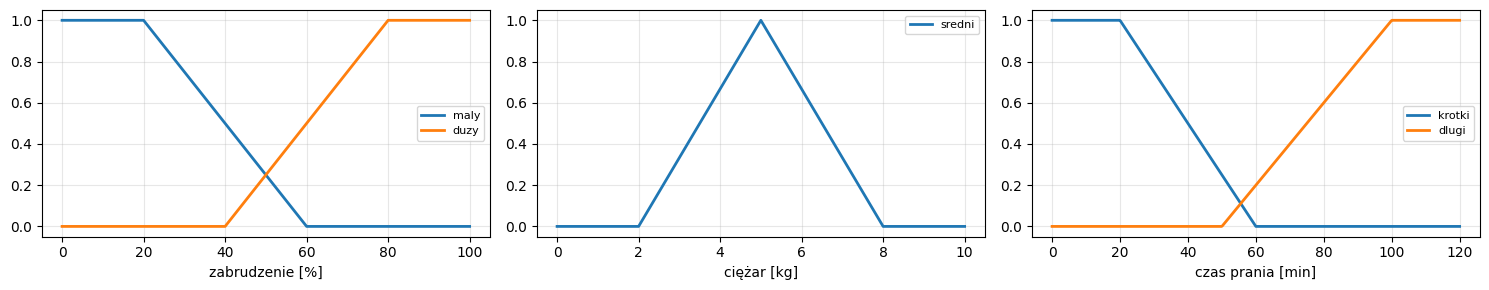

In [47]:
BRUD = {                                   # zabrudzenie [%], 0–100
    "maly": lambda x: L(x, 20, 60),
    "duzy": lambda x: gamma(x, 40, 80),
}
CIEZAR = {                                 # ciężar prania [kg], 0–10
    "sredni": lambda x: t(x, 2, 5, 8),
}
CZAS = {                                   # czas prania [min], 0–120
    "krotki": lambda x: L(x, 20, 60),
    "dlugi":  lambda x: gamma(x, 50, 100),
}

def rysuj_zbiory(BRUD, CIEZAR, CZAS):
    fig, osie = plt.subplots(1, 3, figsize=(15, 3))
    for os_, (nazwa, zbiory, zakres) in zip(osie, [("zabrudzenie [%]", BRUD, 100),
                                                   ("ciężar [kg]", CIEZAR, 10),
                                                   ("czas prania [min]", CZAS, 120)]):
        xs = np.linspace(0, zakres, 501)
        for n, f in zbiory.items():
            os_.plot(xs, f(xs), lw=2, label=n)
        os_.set_xlabel(nazwa); os_.legend(fontsize=8); os_.grid(alpha=.3)
    plt.tight_layout(); plt.show()

rysuj_zbiory(BRUD, CIEZAR, CZAS)

**Pytanie 2a.** Spójrz na wykres ciężaru. Jaki stopień ma „średni” ciężar dla 1 kg i dla 9 kg? Co to może oznaczać dla pralki?

*Twoja odpowiedź:*

**Pytanie 2a.** Dla "średniego" ciężaru stopień dla 1 kg i 9 kg wynosi 0. Oznacza to, że te wartości nie są uznawane za "średnie". Pralka nie ma dodatkowych definicji dla ciężaru, więc dla tych wartości żadna reguła nie zadziała.

### 2.2 Środek ciężkości

Ostatni krok, **wyostrzanie**, zamienia kształt na jedną liczbę. Kształt to dwie tablice: `x` – możliwe czasy prania, `mu` – wysokość kształtu nad każdym czasem. Środek ciężkości to średnia ważona czasów, a wagą jest `mu`:

$$x^* = \frac{x_1 \mu_1 + x_2 \mu_2 + \dots}{\mu_1 + \mu_2 + \dots}$$

Przykład: x = 0, 10, 20, 30 i mu = 0; 1; 0; 0,5 daje (10 · 1 + 30 · 0,5) / (1 + 0,5) = 25 / 1,5 ≈ 16,67.

Zaimplementuj tę funkcję. Jeśli wszystkie `mu` są zerami (żadna reguła nie zadziałała), zwróć `np.nan`.

In [48]:
def srodek_ciezkosci(x, mu):
    x, mu = np.asarray(x, float), np.asarray(mu, float)
    suma_mu = np.sum(mu)
    if suma_mu == 0:
        return np.nan
    return np.sum(x * mu) / suma_mu

In [49]:
# Testy
xs = np.array([0.0, 10.0, 20.0, 30.0])
sprawdz("srodek_ciezkosci", srodek_ciezkosci, [((xs, np.array([0, 1, 1, 0])), 15),
                                             ((xs, np.array([0, 0, 0, 1])), 30),
                                             ((xs, np.array([1, 0, 0, 1])), 15),
                                             ((xs, np.array([0, 1, 0, 0.5])), 50 / 3),
                                             ((xs, np.array([0, 0, 0, 0])), np.nan)])

OK    srodek_ciezkosci


### 2.3 Sterownik z dwiema regułami i mapa sterownika

Reguły zapisujemy jako słownik `{(brud, ciężar): czas}`. `None` znaczy „dowolny ciężar”:

- **R1:** JEŚLI brud **duży** I ciężar **średni**, TO czas **długi**
- **R2:** JEŚLI brud **mały**, TO czas **krótki**

Funkcja `sterownik` wykonuje pięć kroków dla dowolnego zestawu reguł. Nie musisz jej zmieniać – przeczytaj komentarze.

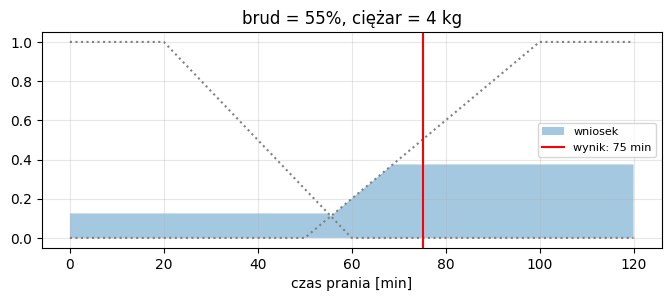

55%, 4 kg -> 75 min


In [50]:
czas = np.linspace(0, 120, 1201)

def srodek_maksimum(x, mu):
    """Inna metoda wyostrzania: środek przedziału, w którym kształt jest najwyższy."""
    if np.max(mu) == 0:
        return np.nan
    return x[np.isclose(mu, np.max(mu))].mean()

def sterownik(brud, ciezar, reguly, T=T_min, implikacja="min", wyostrzanie=None, pokaz=False):
    wyostrzanie = wyostrzanie or srodek_ciezkosci
    # 1. rozmycie wejść
    st_brud = {n: float(f(brud)) for n, f in BRUD.items()}
    st_ciezar = {n: float(f(ciezar)) for n, f in CIEZAR.items()}
    wynik = np.zeros_like(czas)
    for (b, c), wyjscie in reguly.items():
        # 2. siła reguły (None = dowolny ciężar)
        sila = st_brud[b] if c is None else float(T(st_brud[b], st_ciezar[c]))
        # 3. implikacja: "min" przycina zbiór wyjściowy, "iloczyn" go skaluje
        zbior = CZAS[wyjscie](czas)
        wniosek = np.minimum(sila, zbior) if implikacja == "min" else sila * zbior
        # 4. łączenie wniosków
        wynik = S_max(wynik, wniosek)
    # 5. wyostrzanie
    x_star = wyostrzanie(czas, wynik)
    if pokaz:
        plt.figure(figsize=(8, 2.8))
        for n, f in CZAS.items():
            plt.plot(czas, f(czas), ":", c="gray")
        plt.fill_between(czas, wynik, alpha=.4, label="wniosek")
        if not np.isnan(x_star):
            plt.axvline(x_star, c="r", label=f"wynik: {x_star:.0f} min")
        plt.title(f"brud = {brud}%, ciężar = {ciezar} kg"); plt.xlabel("czas prania [min]")
        plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()
    return x_star

REGULY_2 = {
    ("duzy", "sredni"): "dlugi",    # R1
    ("maly", None):     "krotki",   # R2
}

print(f"55%, 4 kg -> {sterownik(55, 4, REGULY_2, pokaz=True):.0f} min")

Sprawdzanie sterownika punkt po punkcie jest żmudne. **Mapa sterownika** liczy wynik dla wszystkich kombinacji zabrudzenia i ciężaru naraz. Białe pola to miejsca, gdzie **żadna reguła nie działa**.

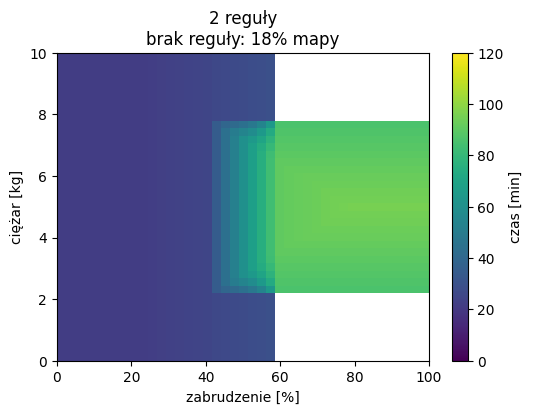

In [53]:
def mapa(reguly, ax=None, tytul="", **ustawienia):
    brudy = np.linspace(0, 100, 41)
    ciezary = np.linspace(0, 10, 41)
    Z = np.array([[sterownik(b, c, reguly, **ustawienia) for b in brudy] for c in ciezary])
    ax = ax or plt.subplots(figsize=(6, 4))[1]
    im = ax.imshow(Z, origin="lower", aspect="auto", extent=[0, 100, 0, 10], cmap="viridis", vmin=0, vmax=120)
    ax.set_xlabel("zabrudzenie [%]"); ax.set_ylabel("ciężar [kg]")
    ax.set_title(f"{tytul}\nbrak reguły: {np.isnan(Z).mean() * 100:.0f}% mapy")
    plt.colorbar(im, ax=ax, label="czas [min]")
    return Z

Z_2 = mapa(REGULY_2, tytul="2 reguły")
plt.show()

**Pytanie 2b.** Gdzie na mapie są białe pola? Opisz słowami, jakie to prania. Co zrobi prawdziwa pralka, gdy sterownik nie zwróci żadnej liczby?

**Pytanie 2c.** Na mapie widać prostokąt, w którym kolor zmienia się gwałtownie. Gdzie leży i skąd się bierze?

*Twoja odpowiedź:*

**Pytanie 2b.** Na mapie białe pola znajdują sie tam, gdzie nie zostały definiowane kryteria. Ciężar ma tylko definicje "średniego" ciężaru dla [2,8], a zabrudzenie jest zdefiniowane "małe" i "duże" dla [0,80]. Czyli dla lekkich i bardzo brudnych ubrań i dla bardzo ciężkich i bardzo brudnych ubrań. W prawdziwym życiu prawdopodobnie włączyła jakiś domyślny tryb uniwersalny.

**Pytanie 2c.** Ten prostokąt znajduję się w zakresie, gdzie według definicji jest pranie "średnio" ciężkie i zabrudzenie jest "duże". Tak widoczny prosokąt pojawia się, gdyż mamy bardzo mało zdefiniowanych definicji dla ciężaru i zabrudzenia, dlatego jak wartość zmienia zakresy widać gwałtowną zmiane koloru.

### 2.4 Pełna baza reguł

Zbuduj pralkę, która ma regułę na **każdą** sytuację: 3 stany zabrudzenia × 3 stany ciężaru = 9 reguł.

1. **Uzupełnij zbiory:** dodaj `"sredni"` do `BRUD`, `"lekki"` i `"ciezki"` do `CIEZAR` oraz `"sredni"` i `"bardzo_dlugi"` do `CZAS`. Możesz zmienić istniejące zbiory. Sąsiednie zbiory muszą się **nakładać**.
2. **Uzupełnij tabelę reguł:** w każdą komórkę słownika `REGULY_9` wpisz `"krotki"`, `"sredni"`, `"dlugi"` albo `"bardzo_dlugi"`.
3. Uruchom mapę i poprawiaj, aż białe pola znikną, a mapa będzie miała sens (więcej brudu i większy ciężar → dłużej).

In [54]:
# TODO 1: uzupełnij zbiory (możesz też zmienić istniejące)
BRUD = {
    "maly":   lambda x: L(x, 0,40),
    "sredni": lambda x: t(x, 35, 50, 60),
    "duzy":   lambda x: gamma(x, 50, 100),
}
CIEZAR = {
    "lekki": lambda x: L(x, 0, 2),
    "sredni": lambda x: t(x, 1.5, 5, 8.5),
    "ciezki": lambda x: gamma(x, 8, 10),
}
CZAS = {
    "krotki": lambda x: L(x, 20, 60),
    "sredni": lambda x: t(x, 40, 60, 80),
    "dlugi":  lambda x: gamma(x, 50, 100),
    "bardzo_dlugi": lambda x: gamma(x, 80, 120),
}

# TODO 2: uzupełnij tabelę reguł (zamień None na nazwę zbioru czasu)
REGULY_9 = {
    ("maly",   "lekki"):  "krotki",
    ("maly",   "sredni"): "krotki",
    ("maly",   "ciezki"): "sredni",
    ("sredni", "lekki"):  "krotki",
    ("sredni", "sredni"): "sredni",
    ("sredni", "ciezki"): "dlugi",
    ("duzy",   "lekki"):  "sredni",
    ("duzy",   "sredni"): "dlugi",
    ("duzy",   "ciezki"): "bardzo_dlugi",
}

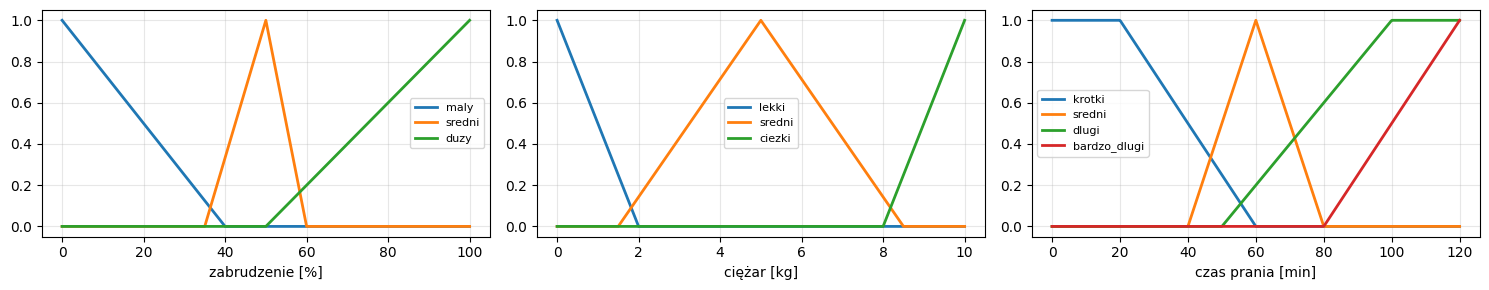

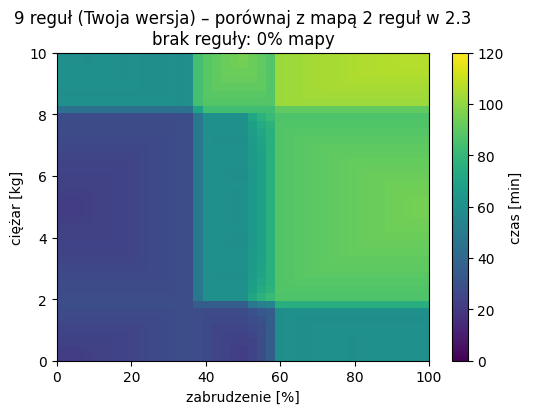

brud 10%, ciężar 1 kg -> 25 min
brud 55%, ciężar 4 kg -> 68 min
brud 90%, ciężar 9 kg -> 104 min


In [55]:
# Uruchamiaj po każdej zmianie
brakuje = [k for k, v in REGULY_9.items() if v is None or k[0] not in BRUD or k[1] not in CIEZAR or v not in CZAS]
if brakuje:
    print("Nie wszystko gotowe – sprawdź te reguły:", brakuje)
else:
    rysuj_zbiory(BRUD, CIEZAR, CZAS)
    Z_9 = mapa(REGULY_9, tytul="9 reguł (Twoja wersja) – porównaj z mapą 2 reguł w 2.3")
    plt.show()
    for b, c in [(10, 1), (55, 4), (90, 9)]:
        print(f"brud {b}%, ciężar {c} kg -> {sterownik(b, c, REGULY_9):.0f} min")

**Pytanie 2d.** Porównaj swoją mapę z mapą osoby obok. Wybierz jeden punkt (np. 70%, 3 kg), dla którego Wasze pralki dają najbardziej różne czasy. Kto ma rację – i jak można by to rozstrzygnąć?

**Pytanie 2e.** 2 wejścia po 3 stany to 9 reguł. Ile reguł trzeba by napisać dla 5 wejść po 3 stany? Co to mówi o ręcznym pisaniu reguł?

*Twoja odpowiedź:*

**Pytanie 2d.**

Nasze różnice wynikają z różnicy między naszymi zakresami definicji i tabelą reguł.Rozwiązać to można przeprowadzając testy z danymi sterownikami i zbadanie, który rzeczywiście lepiej wykonał swoją pracę, czyli który wyczyścił lepiej i efektywniej.

**Pytanie 2e.**

Dla 5 wejść po 3 stany każde wymagane jest 243 reguł. Ręczne pisanie tylu reguł byłoby żmudne i nieefektywne. W takim przypadku lepiej zautomatyzować tworzenie reguł, gdyż przy większej ilości wejść i stanów liczba reguł dramatycznie wzrasta.

### 2.5 Która decyzja projektowa ma największe znaczenie?

Ten sam sterownik ma trzy „pokrętła”: t-normę w części JEŚLI, implikację i metodę wyostrzania. Porównajmy, jak bardzo każde z nich zmienia całą mapę.

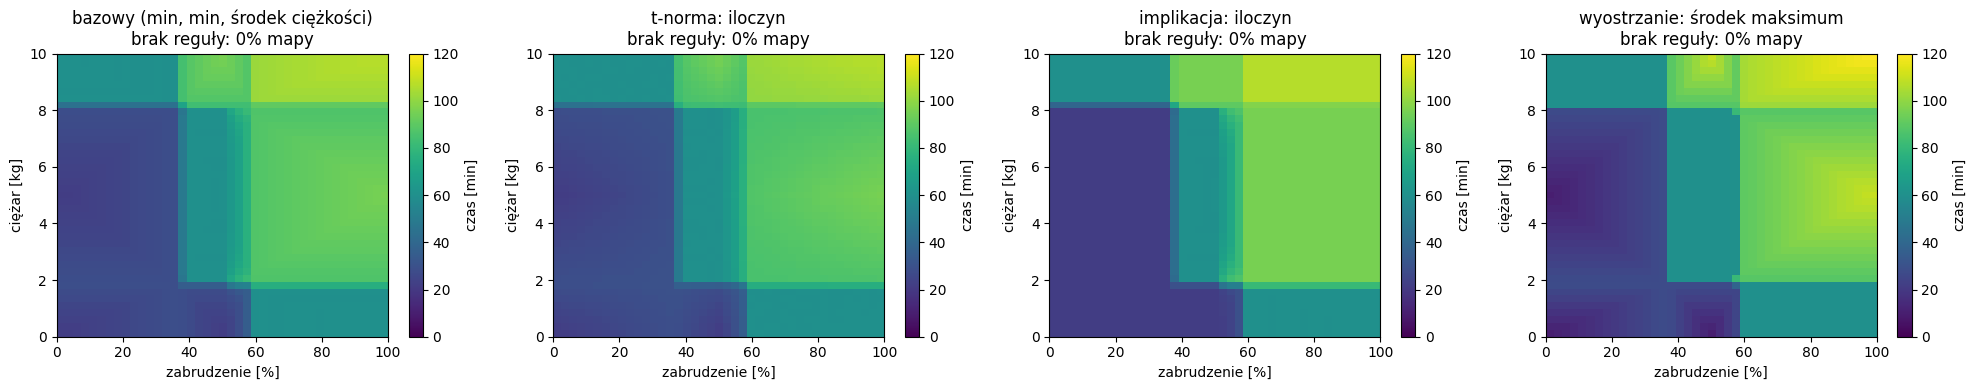

t-norma: iloczyn                 średnia różnica:  0.8 min, największa: 12.6 min
implikacja: iloczyn              średnia różnica:  3.7 min, największa:  8.4 min
wyostrzanie: środek maksimum     średnia różnica:  4.7 min, największa: 25.0 min


In [56]:
warianty = {
    "bazowy (min, min, środek ciężkości)": {},
    "t-norma: iloczyn":                    {"T": T_iloczyn},
    "implikacja: iloczyn":                 {"implikacja": "iloczyn"},
    "wyostrzanie: środek maksimum":        {"wyostrzanie": srodek_maksimum},
}
if brakuje:
    print("Najpierw dokończ 2.4 – ta część używa Twojej pełnej bazy reguł.")
else:
    fig, osie = plt.subplots(1, 4, figsize=(20, 4))
    mapy = {n: mapa(REGULY_9, os_, n, **u) for os_, (n, u) in zip(osie, warianty.items())}
    plt.tight_layout(); plt.show()

    Z0 = mapy["bazowy (min, min, środek ciężkości)"]
    for n, Z in list(mapy.items())[1:]:
        d = np.abs(Z - Z0)
        print(f"{n:<32} średnia różnica: {np.nanmean(d):4.1f} min, największa: {np.nanmax(d):4.1f} min")

**Pytanie 2f.** Które pokrętło najbardziej zmienia sterownik? Która mapa ma wyraźne „schodki” (skoki koloru)?



*Twoja odpowiedź:*

**Pytanie 2f.**

Najbardziej zmieniło wyostrzanie, granice między danymi stanami zostały wyostrzone. Zmiany są teraz gwałtowniejsze i nagłe. Mapa odpowiadająca właśnie wyostrzeniu ma wyraźne "schodki".

### 2.6 Dla chętnych: trzecie wejście

Dodaj wejście **rodzaj tkaniny** z dwoma stanami: `"delikatna"` i `"zwykla"` (np. skala 0–10). Delikatna tkanina powinna skracać pranie.

1. Ile reguł potrzebuje pełna baza dla 3 wejść (3 × 3 × 2)?
2. Funkcja `sterownik` obsługuje tylko dwa wejścia. Co trzeba w niej zmienić, żeby obsłużyła trzecie?
3. Zaproponuj, jak uniknąć pisania wszystkich reguł (np. jedna reguła „JEŚLI tkanina delikatna, TO czas krótki” zamiast dziewięciu).


*Moja odpowiedź:*

**Pytanie 1.**

Pełna baza będzie macierzą trójwymiarową 3 x 3 x 2, czyli potrzebne będzie 9 * 2 = 18 reguł, aby wykonać pełną bazę.

**Pytanie 2.**

Aby funkcja sterownik obsługiwała na raz dwa wejścia i 3 wejścia potrzebna będzie funkcja, która odpowiednio zmienia klucz z (b,c) na przykładowo (b,c,tk) w przypadku 3 wejść. Dodatkowo trzeba obliczyć siłę uwzględniając 3 wejścia.

**Pytanie 3.**

Reguła taka może być zapisana:
(None, None, "delikatna"):    "krotki"
Dla ciężaru i brudu jest None, czyli brane są dowolne wartości. Ta reguła powoduje, że dla dowolnych wartości ciężaru i zabrudzenia, jeżeli tkanina jest delikatna, to czas musi być krótki, aby jej nei zniszczyć.

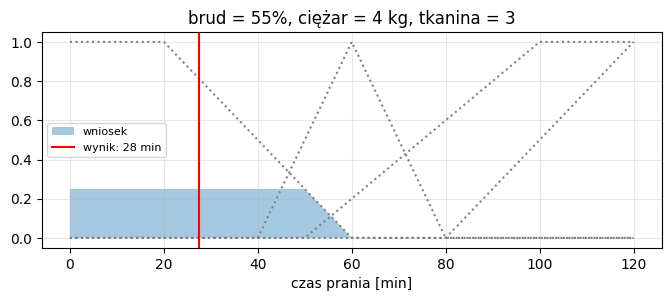

55%, 4 kg, tkanina 5 -> 28 min


In [57]:
czas = np.linspace(0, 120, 1201)

def srodek_maksimum(x, mu):
    """Inna metoda wyostrzania: środek przedziału, w którym kształt jest najwyższy."""
    if np.max(mu) == 0:
        return np.nan
    return x[np.isclose(mu, np.max(mu))].mean()

def sterownik_3war(brud, ciezar, tkanina, reguly, T=T_min, implikacja="min", wyostrzanie=None, pokaz=False):
    wyostrzanie = wyostrzanie or srodek_ciezkosci
    # 1. rozmycie wejść
    st_brud = {n: float(f(brud)) for n, f in BRUD.items()}
    st_ciezar = {n: float(f(ciezar)) for n, f in CIEZAR.items()}
    st_tkanina = {n: float(f(tkanina)) for n, f in TKANINA.items()}
    wynik = np.zeros_like(czas)
    for (b, c, tk), wyjscie in reguly.items():
          stopnie = []
          if b is not None: stopnie.append(st_brud[b])
          if c is not None: stopnie.append(st_ciezar[c])
          if tk is not None: stopnie.append(st_tkanina[tk])
          sila = reduce(T, stopnie) if stopnie else 0.0

          # 3. implikacja: "min" przycina zbiór wyjściowy, "iloczyn" go skaluje
          zbior = CZAS[wyjscie](czas)
          wniosek = np.minimum(sila, zbior) if implikacja == "min" else sila * zbior
          # 4. łączenie wniosków
          wynik = S_max(wynik, wniosek)
    # 5. wyostrzanie
    x_star = wyostrzanie(czas, wynik)
    if pokaz:
        plt.figure(figsize=(8, 2.8))
        for n, f in CZAS.items():
            plt.plot(czas, f(czas), ":", c="gray")
        plt.fill_between(czas, wynik, alpha=.4, label="wniosek")
        if not np.isnan(x_star):
            plt.axvline(x_star, c="r", label=f"wynik: {x_star:.0f} min")
        plt.title(f"brud = {brud}%, ciężar = {ciezar} kg, tkanina = {tkanina}"); plt.xlabel("czas prania [min]")
        plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()
    return x_star

REGULY_2 = {
    ("duzy", "sredni", "zwykla"): "dlugi",    # R1
    ("maly", None, "zwykla"):     "krotki",   # R2
    (None, None, "delikatna"):    "krotki",   # R3 (regula do skracania czasu gdy tkanina jest delikatna)
}

print(f"55%, 4 kg, tkanina 5 -> {sterownik_3war(55, 4, 3, REGULY_2, pokaz=True):.0f} min")